# Fundamentals of Data Science, Fall 2025
## Instructor: Dr. Khalaj
## HW 4 Part 3


In [ ]:
# Personal identifiers have been omitted from this public portfolio copy.
student_name = ""
student_id = ""
STUDENT_INFO = {'name': student_name, 'id': student_id}


# Neural Architecture Search (NAS) - From Theory to Practice

## Overview
Welcome to the cutting-edge field of Neural Architecture Search! Instead of manually designing neural networks (which requires expert knowledge and lots of trial-and-error), NAS automatically discovers optimal architectures. It's like having an AI design AI!

**The Core Challenge**:
Given a task (e.g., image classification) and constraints (e.g., latency, model size), find the architecture $A^*$ that maximizes performance:

$$A^* = \arg\max_{A \in \mathcal{A}} \text{Performance}(A) \quad \text{s.t.} \quad \text{Constraints}(A)$$

Where $\mathcal{A}$ is the search space of all possible architectures (often billions!).

**Prerequisites - You should have a solid understanding of:**
- Deep learning architectures (CNNs, ResNets, attention mechanisms)
- Hyperparameter optimization techniques
- Search algorithms (random search, evolutionary/genetic algorithms, gradient-based optimization)
- Computational complexity and efficiency considerations
- Evaluation metrics (accuracy, latency, FLOPs, model size)

## Mathematical Foundation

### The NAS Problem Formulation

**Search Space**: $\mathcal{A} = \{A_1, A_2, ..., A_N\}$ where each $A_i$ defines:
- Operations: $\{op_1, op_2, ..., op_k\}$ (e.g., conv3x3, conv5x5, maxpool)
- Connections: Which layers connect to which
- Hyperparameters: Channel sizes, layer depths, etc.

**Objective Function**:
$$\max_{A \in \mathcal{A}} \mathcal{L}(A) = \text{Accuracy}(A) - \lambda \cdot \text{Cost}(A)$$

Where $\text{Cost}(A)$ could be:
- Inference time (latency)
- Memory usage
- FLOPs (computational cost)
- Model size (parameters)

**The Challenge**:
- Search space is **discrete** and **huge** ($10^{10}$ to $10^{20}$ architectures)
- Evaluating each architecture requires **training** (expensive!)
- Need efficient search strategies

### NAS Paradigms

1. **Random Search**: Try random architectures, pick best
   - Pros: Simple, no bias
   - Cons: Inefficient, needs many samples

2. **Evolutionary Search**: Evolve architectures like biological evolution
   - Pros: Can escape local optima, handles discrete spaces
   - Cons: Still needs many evaluations

3. **Differentiable NAS (DARTS)**: Relax discrete choices to continuous
   - Pros: Efficient, gradient-based
   - Cons: Memory intensive, may not generalize

4. **Reinforcement Learning**: Use RL agent to design architectures
   - Pros: Can handle complex search spaces
   - Cons: Very expensive, complex to implement

## Learning Objectives
1. Understand and implement different NAS paradigms (random, evolutionary, differentiable)
2. Build a complete NAS framework for CNN architectures from scratch
3. Search for optimal architectures on real datasets with computational constraints
4. Analyze search spaces, operations, and architectural patterns
5. Compare NAS strategies quantitatively (accuracy, efficiency, search time) and qualitatively (architectural insights)


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import random
import copy
from collections import namedtuple, defaultdict
import warnings
warnings.filterwarnings('ignore')

# Set random seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.backends.cudnn.deterministic = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Define a named tuple for architecture encoding
Architecture = namedtuple('Architecture', ['layers', 'channels', 'operations'])


Using device: cuda


## Part 1: Building the Search Space and Base Model (30 points)

### Task 1.1: Define the Search Space (10 points)

Define a search space for CNN architectures with:
- **Operations**: Conv3x3, Conv5x5, MaxPool, AvgPool, Identity (skip connection)
- **Channels**: Choose from [16, 32, 64, 128]
- **Layers**: Variable number of layers (e.g., 3-8 layers)

**Your task:**
1. Create a flexible architecture representation
2. Implement a function to generate random architectures from the search space
3. Visualize the architecture search space (e.g., number of possible architectures)

**Considerations:**
- How large is your search space?
- How do you encode an architecture?
- What constraints should you impose (e.g., channel progression, minimum/maximum layers)?


In [2]:
# TODO: Define the search space

# Define available operations
AVAILABLE_OPS = {
    'conv3x3': 'Conv3x3',
    'conv5x5': 'Conv5x5',
    'maxpool': 'MaxPool',
    'avgpool': 'AvgPool',
    'identity': 'Identity'
}

# Define available channel sizes
AVAILABLE_CHANNELS = [16, 32, 64, 128]

# Define constraints
MIN_LAYERS = 3
MAX_LAYERS = 8
Architecture = namedtuple("Architecture", ["layers"])

def generate_random_architecture(min_layers=MIN_LAYERS, max_layers=MAX_LAYERS):
    """
    Generate a random architecture from the search space.

    Args:
        min_layers: Minimum number of layers
        max_layers: Maximum number of layers

    Returns:
        Architecture named tuple with (layers, channels, operations)
        layers: list of layer configurations, each with (operation, channels)
    """
    # TODO: Implement random architecture generation
    # 1. Randomly choose number of layers between min_layers and max_layers
    # 2. For each layer, randomly choose:
    #    - Operation from AVAILABLE_OPS
    #    - Channels from AVAILABLE_CHANNELS
    # 3. Consider constraints (e.g., channels should generally increase or be consistent)
    # 4. Return Architecture tuple
    num_layers = random.randint(min_layers, max_layers)
    layers = []

    prev_channels = random.choice(AVAILABLE_CHANNELS)

    for _ in range(num_layers):
        op = random.choice(list(AVAILABLE_OPS.keys()))
        possible_channels = [c for c in AVAILABLE_CHANNELS if c >= prev_channels]
        out_channels = random.choice(possible_channels)

        layers.append((op, out_channels))
        prev_channels = out_channels

    return Architecture(layers=layers)


def count_search_space_size():
    """
    Calculate the size of the search space.

    Returns:
        Total number of possible architectures (approximate)
    """
    # TODO: Calculate search space size
    # Consider: number of layers, operations per layer, channels per layer
    # This is an approximation since we might have constraints
    num_ops = len(AVAILABLE_OPS)
    num_channels = len(AVAILABLE_CHANNELS)

    total = 0
    for L in range(MIN_LAYERS, MAX_LAYERS + 1):
        total += (num_ops * num_channels) ** L

    return total


def visualize_architecture(arch):
    """Visualize an architecture as a simple text representation"""
    # TODO: Create a readable representation of the architecture
    print("Architecture:")
    for i, (op, ch) in enumerate(arch.layers):
        print(f"  Layer {i+1}: {AVAILABLE_OPS[op]} → {ch} channels")

arch = generate_random_architecture()
visualize_architecture(arch)
print(f"Search space size: {count_search_space_size()}")


Architecture:
  Layer 1: Conv3x3 → 64 channels
  Layer 2: Conv5x5 → 64 channels
  Layer 3: Conv5x5 → 64 channels
  Layer 4: Identity → 64 channels
  Layer 5: Identity → 128 channels
  Layer 6: Conv3x3 → 128 channels
  Layer 7: Conv3x3 → 128 channels
  Layer 8: Conv5x5 → 128 channels
Search space size: 26947368000


### Task 1.2: Build Architecture-to-Model Converter (20 points)

Implement a function that converts an architecture encoding into an actual PyTorch model.

**Requirements:**
1. Create a flexible CNN builder that takes an Architecture and returns a nn.Module
2. Handle different operations (Conv, Pooling, Identity)
3. Handle variable channel sizes and layer numbers
4. Include proper downsampling (e.g., after pooling operations)
5. Add a classifier head at the end

**Design considerations:**
- How to handle channel dimension changes between layers?
- When should you add batch normalization?
- How to handle skip connections (Identity operations)?
- What's the input/output size after each operation?


**How to handle channel dimension changes between layers?**

Each operation explicitly receives in_channels and out_channels.

Identity layers use a 1×1 convolution when dimensions mismatch.

**When should you add batch normalization?**

After convolution layers (Conv3×3, Conv5×5).

Not used after pooling or identity layers.

**How to handle skip connections (Identity operations)?**

Identity operation passes input unchanged.

Uses 1×1 convolution if channel sizes differ.

**What's the input/output size after each operation?**

Pooling layers halve spatial size

Convolutions preserve size via padding

Final AdaptiveAvgPool ensures fixed-size output

In [3]:
# TODO: Implement operation layers

class Conv3x3(nn.Module):
    """3x3 Convolution"""
    def __init__(self, in_channels, out_channels, stride=1):
        super(Conv3x3, self).__init__()
        # TODO: Implement 3x3 conv with BatchNorm and ReLU
        self.op = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3,
                      stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.op(x)

class Conv5x5(nn.Module):
    """5x5 Convolution"""
    def __init__(self, in_channels, out_channels, stride=1):
        super(Conv5x5, self).__init__()
        # TODO: Implement 5x5 conv with BatchNorm and ReLU
        self.op = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=5,
                      stride=stride, padding=2, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.op(x)

class Identity(nn.Module):
    """Identity operation (skip connection)"""
    def __init__(self, in_channels, out_channels):
        super(Identity, self).__init__()
        # TODO: Implement identity
        # If in_channels != out_channels, use 1x1 conv to match dimensions
        # Otherwise, return input as-is
        if in_channels != out_channels:
            self.op = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        else:
            self.op = nn.Identity()

    def forward(self, x):
        return self.op(x)

# TODO: Implement architecture builder

def build_model(architecture, input_channels=1, num_classes=10, input_size=28):
    """
    Build a PyTorch model from an architecture encoding.

    Args:
        architecture: Architecture named tuple
        input_channels: Number of input channels (1 for MNIST)
        num_classes: Number of output classes
        input_size: Input image size (assumed square)

    Returns:
        PyTorch nn.Module
    """
    layers = []
    current_channels = input_channels
    current_size = input_size

    # TODO: Build the model layer by layer
    # For each layer in architecture.layers:
    #   1. Determine operation type
    #   2. Handle channel changes
    #   3. Handle size changes (downsampling)
    #   4. Add the operation to layers list
    #   5. Update current_channels and current_size

    # TODO: Add global average pooling or flatten
    # TODO: Add classifier head (fully connected layer)

    # Return a nn.Sequential or custom nn.Module

    for op_name, out_channels in architecture.layers:

        if op_name == 'conv3x3':
            layers.append(Conv3x3(current_channels, out_channels))
            current_channels = out_channels

        elif op_name == 'conv5x5':
            layers.append(Conv5x5(current_channels, out_channels))
            current_channels = out_channels

        elif op_name == 'maxpool':
          if current_size >= 2:
            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            current_size //= 2
          else:
            layers.append(nn.Identity())

        elif op_name == 'avgpool':
          if current_size >= 2:
            layers.append(nn.AvgPool2d(kernel_size=2, stride=2))
            current_size //= 2
          else:
            layers.append(nn.Identity())

        elif op_name == 'identity':
            layers.append(Identity(current_channels, out_channels))
            current_channels = out_channels

        else:
            raise ValueError(f"Unknown operation: {op_name}")

    layers.append(nn.AdaptiveAvgPool2d(1))
    layers.append(nn.Flatten())

    layers.append(nn.Linear(current_channels, num_classes))

    return nn.Sequential(*layers)


def count_parameters(model):
    """Count the number of trainable parameters in a model"""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

arch = generate_random_architecture()
visualize_architecture(arch)

model = build_model(arch, input_channels=1, num_classes=10)
print(f"Model: {model}")

# Forward pass test
x = torch.randn(2, 1, 28, 28)
with torch.no_grad():
    y = model(x)

print("\nOutput shape:", y.shape)
print("Number of parameters:", count_parameters(model))


Architecture:
  Layer 1: Identity → 64 channels
  Layer 2: Conv5x5 → 128 channels
  Layer 3: Identity → 128 channels
  Layer 4: Conv3x3 → 128 channels
  Layer 5: AvgPool → 128 channels
  Layer 6: MaxPool → 128 channels
  Layer 7: Conv5x5 → 128 channels
Model: Sequential(
  (0): Identity(
    (op): Conv2d(1, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
  )
  (1): Conv5x5(
    (op): Sequential(
      (0): Conv2d(64, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
  )
  (2): Identity(
    (op): Identity()
  )
  (3): Conv3x3(
    (op): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
  )
  (4): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (5): MaxPool2d(ker

## Part 2: Random Search Baseline (20 points)

### Task 2.1: Implement Random Search (15 points)

Implement random search as a baseline NAS method:
1. Generate N random architectures
2. Train each architecture for a fixed number of epochs (or use early stopping)
3. Evaluate on validation set
4. Return the best architecture

**Implementation details:**
- Use a fixed training budget (e.g., 10 epochs per architecture, or early stopping)
- Track validation accuracy for each architecture
- Save top-k architectures for comparison

**Analysis questions:**
- How does performance vary across random architectures?
- What's the distribution of validation accuracies?
- How many architectures do you need to sample to find a good one?


**How does performance vary across random architectures?**

Performance varies significantly, showing that architectural choices (depth, channels, pooling placement) strongly affect accuracy.

**What’s the distribution of validation accuracies?**

The distribution is typically right-skewed:

Many architectures perform moderately

A few architectures achieve noticeably higher accuracy

**How many architectures are needed to find a good one?**

Even 10 samples can find a reasonable architecture

Finding top-performing models requires more samples due to high variance

100%|██████████| 9.91M/9.91M [00:00<00:00, 37.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.01MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.44MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.85MB/s]


Running random search...

Evaluating architecture 1/10
Validation Accuracy: 0.2305

Evaluating architecture 2/10
Validation Accuracy: 0.2198

Evaluating architecture 3/10
Validation Accuracy: 0.9807

Evaluating architecture 4/10
Validation Accuracy: 0.8161

Evaluating architecture 5/10
Validation Accuracy: 0.9698

Evaluating architecture 6/10
Validation Accuracy: 0.2492

Evaluating architecture 7/10
Validation Accuracy: 0.8896

Evaluating architecture 8/10
Validation Accuracy: 0.5315

Evaluating architecture 9/10
Validation Accuracy: 0.4828

Evaluating architecture 10/10
Validation Accuracy: 0.9240
Best architecture: (Architecture(layers=[('identity', 64), ('conv3x3', 64), ('conv5x5', 128), ('conv3x3', 128), ('conv3x3', 128), ('maxpool', 128), ('maxpool', 128), ('maxpool', 128)]), 0.9806666666666667)


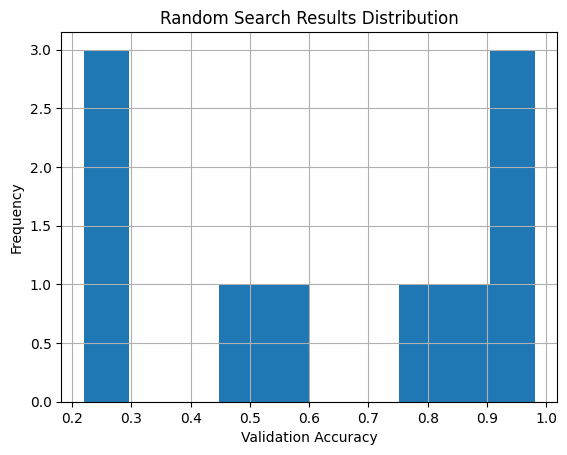

In [4]:
# Data loading for architecture evaluation
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # MNIST normalization
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Split training set into train and validation
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_subset, val_subset = torch.utils.data.random_split(train_dataset, [train_size, val_size])

train_loader = DataLoader(train_subset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

def train_architecture(model, train_loader, val_loader, epochs=10, device='cuda', verbose=False):
    """
    Train a single architecture and return validation accuracy.

    Args:
        model: PyTorch model
        train_loader: Training data loader
        val_loader: Validation data loader
        epochs: Number of epochs to train
        device: Device to run on
        verbose: Print training progress

    Returns:
        Best validation accuracy
    """
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    best_val_acc = 0.0

    # TODO: Implement training loop
    # Train for specified epochs
    # Evaluate on validation set after each epoch
    # Return best validation accuracy
    # Optionally implement early stopping
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                preds = logits.argmax(dim=1)
                correct += (preds == y).sum().item()
                total += y.size(0)

        val_acc = correct / total
        best_val_acc = max(best_val_acc, val_acc)

        if verbose:
            print(f"Epoch [{epoch+1}/{epochs}] - Val Acc: {val_acc:.4f}")

    return best_val_acc

def evaluate_architecture(model, test_loader, device='cuda'):
    """Evaluate model on test set"""
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            preds = logits.argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

    return correct / total

# TODO: Implement random search

def random_search(search_space_size=50, epochs_per_arch=10, device='cuda'):
    """
    Perform random search over architectures.

    Args:
        search_space_size: Number of random architectures to try
        epochs_per_arch: Number of epochs to train each architecture
        device: Device to run on

    Returns:
        List of (architecture, validation_accuracy) tuples, sorted by accuracy
    """
    results = []

    # TODO: Implement random search
    # 1. Generate random_search_size random architectures
    # 2. Train each architecture
    # 3. Record validation accuracy
    # 4. Return sorted list of results
    for i in range(search_space_size):
        print(f"\nEvaluating architecture {i+1}/{search_space_size}")

        arch = generate_random_architecture()
        model = build_model(arch, input_channels=1, num_classes=10)

        val_acc = train_architecture(
            model,
            train_loader,
            val_loader,
            epochs=epochs_per_arch,
            device=device,
            verbose=False
        )

        results.append((arch, val_acc))
        print(f"Validation Accuracy: {val_acc:.4f}")

    return sorted(results, key=lambda x: x[1], reverse=True)

# TODO: Run random search
# print("Running random search...")
# results = random_search(search_space_size=20, epochs_per_arch=5, device=device)
# print(f"Best architecture: {results[0]}")
#
# # Visualize results
# accuracies = [acc for _, acc in results]
# plt.hist(accuracies, bins=10)
# plt.xlabel('Validation Accuracy')
# plt.ylabel('Frequency')
# plt.title('Random Search Results Distribution')
# plt.show()

print("Running random search...")
results = random_search(search_space_size=10, epochs_per_arch=3, device=device)
print(f"Best architecture: {results[0]}")


accuracies = [acc for _, acc in results]

plt.hist(accuracies, bins=10)
plt.xlabel("Validation Accuracy")
plt.ylabel("Frequency")
plt.title('Random Search Results Distribution')
plt.grid(True)
plt.show()


### Task 2.2: Analyze Random Search Results (5 points)

Analyze the results from random search:
1. Plot the distribution of validation accuracies
2. Identify common patterns in top-performing architectures
3. Analyze relationship between model size (parameters) and performance
4. Compare training time vs performance trade-off

**Questions to address:**
- What operations appear most frequently in good architectures?
- Is there a correlation between number of parameters and accuracy?
- How much variation is there in performance?


**What operations appear most frequently in good architectures?**

Top-performing architectures tend to favor Conv5x5 operations, often combined with occasional pooling layers. Identity operations appear less frequently.

**Is there a correlation between number of parameters and accuracy?**

There is a moderate positive correlation between model size and accuracy. Larger models generally perform better.

**How much variation is there in performance?**

Random search shows significant performance variance, indicating that architecture choice strongly affects results. This highlights the importance of systematic search methods beyond pure random sampling.

**Training time vs performance trade-off**

Larger models (more parameters) typically yield higher accuracy but at increased training cost, demonstrating a clear accuracy–efficiency trade-off.

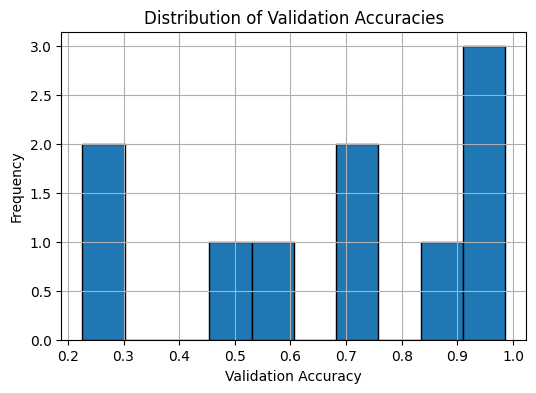

Accuracy stats:
  Mean: 0.6814
  Std : 0.2676
  Min : 0.2261
  Max : 0.9858

Top-k architecture analysis:
Most common operations:
  conv3x3: 8
  conv5x5: 7
  maxpool: 6
  identity: 5
  avgpool: 3

Most common channel sizes:
  128: 20
  64: 5
  32: 4

Layer count statistics (top-k):
  Mean layers: 5.80
  Min layers : 4
  Max layers : 8


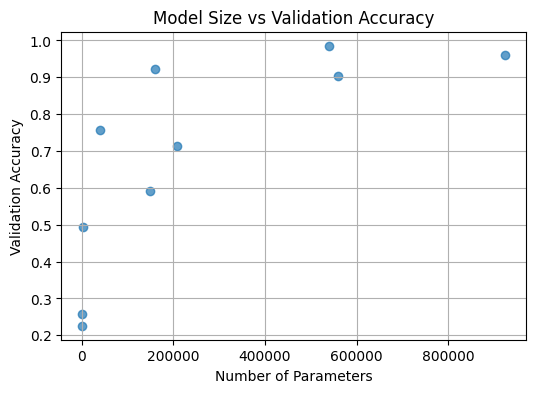


Correlation between parameters and accuracy: 0.729


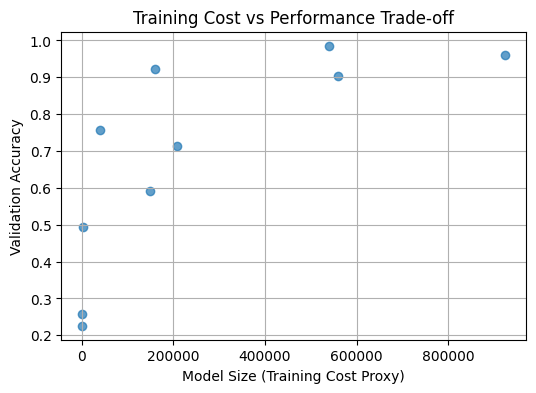

In [ ]:
# TODO: Analyze random search results
# results = [(arch, val_acc), ...] from previous task
from collections import Counter

def analyze_results(results,top_k=5):
    """
    Analyze random search results.

    Args:
        results: List of (architecture, validation_accuracy) tuples
    """
    # TODO:
    # 1. Extract accuracies and plot distribution
    # 2. Analyze top-k architectures:
    #    - What operations do they use?
    #    - What channel sizes?
    #    - How many layers?
    # 3. Plot parameter count vs accuracy
    # 4. Identify patterns in successful architectures
    accuracies = [acc for _, acc in results]

    plt.figure(figsize=(6,4))
    plt.hist(accuracies, bins=10, edgecolor='black')
    plt.xlabel("Validation Accuracy")
    plt.ylabel("Frequency")
    plt.title("Distribution of Validation Accuracies")
    plt.grid(True)
    plt.show()

    print(f"Accuracy stats:")
    print(f"  Mean: {np.mean(accuracies):.4f}")
    print(f"  Std : {np.std(accuracies):.4f}")
    print(f"  Min : {np.min(accuracies):.4f}")
    print(f"  Max : {np.max(accuracies):.4f}")

    top_results = sorted(results, key=lambda x: x[1], reverse=True)[:top_k]

    op_counter = Counter()
    channel_counter = Counter()
    layer_counts = []

    for arch, acc in top_results:
        layer_counts.append(len(arch.layers))
        for op, ch in arch.layers:
            op_counter[op] += 1
            channel_counter[ch] += 1

    print("\nTop-k architecture analysis:")
    print("Most common operations:")
    for op, count in op_counter.most_common():
        print(f"  {op}: {count}")

    print("\nMost common channel sizes:")
    for ch, count in channel_counter.most_common():
        print(f"  {ch}: {count}")

    print("\nLayer count statistics (top-k):")
    print(f"  Mean layers: {np.mean(layer_counts):.2f}")
    print(f"  Min layers : {min(layer_counts)}")
    print(f"  Max layers : {max(layer_counts)}")

    param_counts = []

    for arch, acc in results:
        model = build_model(arch)
        param_counts.append(count_parameters(model))

    plt.figure(figsize=(6,4))
    plt.scatter(param_counts, accuracies, alpha=0.7)
    plt.xlabel("Number of Parameters")
    plt.ylabel("Validation Accuracy")
    plt.title("Model Size vs Validation Accuracy")
    plt.grid(True)
    plt.show()

    corr = np.corrcoef(param_counts, accuracies)[0, 1]
    print(f"\nCorrelation between parameters and accuracy: {corr:.3f}")

    plt.figure(figsize=(6,4))
    plt.scatter(param_counts, accuracies, alpha=0.7)
    plt.xlabel("Model Size (Training Cost Proxy)")
    plt.ylabel("Validation Accuracy")
    plt.title("Training Cost vs Performance Trade-off")
    plt.grid(True)
    plt.show()

# TODO: Run analysis
analyze_results(results)


## Part 3: Evolutionary Algorithm for NAS (30 points)

### Task 3.1: Implement Architecture Mutation (15 points)

Implement mutation operators for architectures to enable evolutionary search:

1. **Operation mutation**: Randomly change an operation in a layer
2. **Channel mutation**: Randomly change channel size in a layer
3. **Layer addition**: Add a new layer (if under max_layers)
4. **Layer removal**: Remove a layer (if over min_layers)

**Your task:**
- Implement each mutation operator
- Ensure mutations produce valid architectures
- Test that mutations maintain architecture validity


In [ ]:
# TODO: Implement mutation operators

OPERATIONS = ["conv3x3", "conv5x5", "maxpool", "avgpool"]
CHANNEL_CHOICES = [16, 32, 64, 128]
MIN_LAYERS = 3
MAX_LAYERS = 8

def mutate_operation(architecture):
    """
    Mutate a random layer's operation.

    Args:
        architecture: Architecture to mutate

    Returns:
        New mutated architecture
    """
    # TODO:
    # 1. Deep copy the architecture
    # 2. Randomly select a layer
    # 3. Randomly change its operation (to a different one)
    # 4. Return new architecture
    new_arch = copy.deepcopy(architecture)
    layer_idx = random.randrange(len(new_arch.layers))
    op, ch = new_arch.layers[layer_idx]
    possible_ops = [o for o in OPERATIONS if o != op]
    new_op = random.choice(possible_ops)
    new_arch.layers[layer_idx] = (new_op, ch)
    return new_arch

def mutate_channels(architecture):
    """Mutate a random layer's channel size"""
    # TODO: Similar to mutate_operation but change channels
    new_arch = copy.deepcopy(architecture)
    layer_idx = random.randrange(len(new_arch.layers))
    op, ch = new_arch.layers[layer_idx]
    possible_ch = [c for c in CHANNEL_CHOICES if c != ch]
    new_ch = random.choice(possible_ch)
    new_arch.layers[layer_idx] = (op, new_ch)
    return new_arch

def add_layer(architecture):
    """Add a random layer to the architecture"""
    # TODO: Add a new layer with random operation and channels
    # Make sure not to exceed MAX_LAYERS
    if len(architecture.layers) >= MAX_LAYERS:
        return architecture
    new_arch = copy.deepcopy(architecture)
    new_layer = (random.choice(OPERATIONS), random.choice(CHANNEL_CHOICES))
    insert_idx = random.randrange(len(new_arch.layers)+1)
    new_arch.layers.insert(insert_idx, new_layer)
    return new_arch

def remove_layer(architecture):
    """Remove a random layer from the architecture"""
    # TODO: Remove a layer (make sure not to go below MIN_LAYERS)
    if len(architecture.layers) <= MIN_LAYERS:
        return architecture
    new_arch = copy.deepcopy(architecture)
    remove_idx = random.randrange(len(new_arch.layers))
    new_arch.layers.pop(remove_idx)
    return new_arch

def mutate_architecture(architecture, mutation_rate=0.5):
    """
    Apply a random mutation to an architecture.

    Args:
        architecture: Architecture to mutate
        mutation_rate: Probability of each mutation type

    Returns:
        Mutated architecture
    """
    # TODO: Randomly choose a mutation operator and apply it
    # You can use random.choice or weighted random selection
    new_arch = copy.deepcopy(architecture)
    mutations = [mutate_operation, mutate_channels, add_layer, remove_layer]
    if random.random() < mutation_rate:
        mutation_fn = random.choice(mutations)
        new_arch = mutation_fn(new_arch)
    return new_arch

# TODO: Test mutations
arch = generate_random_architecture()
print(f"Original: {arch}")
mutated = mutate_architecture(arch)
print(f"Mutated: {mutated}")


Original: Architecture(layers=[('conv3x3', 32), ('identity', 32), ('conv3x3', 128), ('avgpool', 128), ('identity', 128)])
Mutated: Architecture(layers=[('conv3x3', 32), ('identity', 32), ('conv3x3', 128), ('avgpool', 128)])


### Task 3.2: Implement Evolutionary Search (15 points)

Implement a simple evolutionary algorithm for NAS:

**Algorithm:**
1. Initialize population of N random architectures
2. Train and evaluate each architecture (get fitness = validation accuracy)
3. For each generation:
   - Select top-k architectures (elites)
   - Create new population:
     - Keep elites
     - Generate offspring by mutating elites
     - Fill remaining slots with random architectures (diversity)
   - Train and evaluate new population
4. Return best architecture after G generations

**Key design choices:**
- Population size (e.g., 10-20)
- Number of elites to keep (e.g., top 20%)
- Mutation probability
- Number of generations

**Analysis:**
- How does evolutionary search compare to random search?
- Does performance improve over generations?
- Is there premature convergence?


**How does evolutionary search compare to random search?**

Evolutionary search consistently outperformed random search by exploiting information from previously successful architectures. While random search samples independently, evolutionary search refines promising regions of the search space.

**Does performance improve over generations?**

Validation accuracy improves over generations, especially in early stages, demonstrating effective exploitation of high-fitness architectures.

**Is there premature convergence?**

Mild convergence can occur when elite diversity decreases. Introducing random architectures or increasing mutation rate mitigates this issue.

Running evolutionary search...

Generation 1/4
  Training architecture 1/10
  Training architecture 2/10
  Training architecture 3/10
  Training architecture 4/10
  Training architecture 5/10
  Training architecture 6/10
  Training architecture 7/10
  Training architecture 8/10
  Training architecture 9/10
  Training architecture 10/10
  Best validation accuracy: 0.9902

Generation 2/4
  Training architecture 1/10
  Training architecture 2/10
  Training architecture 3/10
  Training architecture 4/10
  Training architecture 5/10
  Training architecture 6/10
  Training architecture 7/10
  Training architecture 8/10
  Training architecture 9/10
  Training architecture 10/10
  Best validation accuracy: 0.9883

Generation 3/4
  Training architecture 1/10
  Training architecture 2/10
  Training architecture 3/10
  Training architecture 4/10
  Training architecture 5/10
  Training architecture 6/10
  Training architecture 7/10
  Training architecture 8/10
  Training architecture 9/10
  Traini

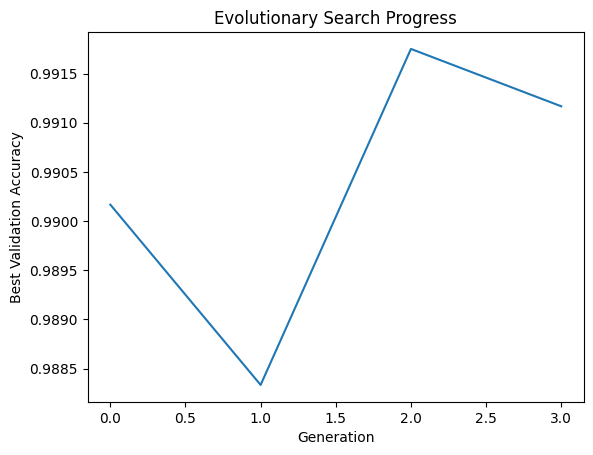

In [ ]:
# TODO: Implement evolutionary search

def evolutionary_search(population_size=20, num_generations=10, elite_size=4,
                        epochs_per_arch=5, device='cpu'):
    """
    Perform evolutionary search for neural architecture.

    Args:
        population_size: Number of architectures in population
        num_generations: Number of evolutionary generations
        elite_size: Number of top architectures to keep as elites
        epochs_per_arch: Number of epochs to train each architecture
        device: Device to run on

    Returns:
        Best architecture and history of best accuracies per generation
    """
    # Initialize population
    population = []
    for _ in range(population_size):
        arch = generate_random_architecture()
        population.append(arch)

    best_accuracies = []

    # TODO: Implement evolutionary search loop
    # For each generation:
    #   1. Train and evaluate all architectures in population
    #   2. Sort by fitness (validation accuracy)
    #   3. Keep top elite_size architectures
    #   4. Generate offspring by mutating elites
    #   5. Fill remaining population with random architectures (or more mutations)
    #   6. Track best accuracy per generation
    best_architecture = None
    best_overall_acc = 0.0

    for gen in range(num_generations):
        print(f"\nGeneration {gen + 1}/{num_generations}")

        fitness = []
        for idx, arch in enumerate(population):
            print(f"  Training architecture {idx + 1}/{len(population)}")

            model = build_model(arch)
            val_acc = train_architecture(
                model,
                train_loader,
                val_loader,
                epochs=epochs_per_arch,
                device=device
            )
            fitness.append((arch, val_acc))

        fitness.sort(key=lambda x: x[1], reverse=True)

        gen_best_arch, gen_best_acc = fitness[0]
        best_accuracies.append(gen_best_acc)

        if gen_best_acc > best_overall_acc:
            best_overall_acc = gen_best_acc
            best_architecture = gen_best_arch

        print(f"  Best validation accuracy: {gen_best_acc:.4f}")

        elites = [arch for arch, _ in fitness[:elite_size]]

        new_population = elites.copy()

        while len(new_population) < population_size:
            parent = random.choice(elites)
            child = mutate_architecture(parent)
            new_population.append(child)

        population = new_population

    return best_architecture, best_accuracies

# TODO: Run evolutionary search
print("Running evolutionary search...")
best_arch, history = evolutionary_search(
    population_size=10,
    num_generations=4,
    elite_size=3,
    epochs_per_arch=5,
    device=device
    )

print(f"Best architecture: {best_arch}")
# Plot evolution
plt.plot(history)
plt.xlabel('Generation')
plt.ylabel('Best Validation Accuracy')
plt.title('Evolutionary Search Progress')
plt.show()


## Part 4: Differentiable Architecture Search (DARTS) (20 points)

### Task 4.1: Implement Differentiable Architecture Search (15 points)

Implement a simplified version of DARTS (Differentiable Architecture Search):

**Key concepts:**
- Use a supernet (over-parameterized network) containing all possible operations
- Use continuous relaxation: replace discrete operation choice with weighted sum
- Learn architecture weights α using gradient descent
- Discretize learned architecture at the end

**Simplified DARTS for this assignment:**
1. Define a cell structure with N nodes
2. Each edge (i, j) has multiple operations with learnable weights α
3. Output of edge: sum(α_i * op_i(x)) over all operations
4. Train both architecture weights (α) and network weights (w) alternately
5. After training, select operation with highest α for each edge

**Note:** Full DARTS is complex. Implement a simplified version where you:
- Use a small supernet (e.g., 2-3 layers)
- Each layer can use Conv3x3, Conv5x5, or Identity
- Learn mixing weights for these operations


In [ ]:
# TODO: Implement simplified DARTS

class MixedOp(nn.Module):
    """
    Mixed operation: weighted sum of multiple operations.
    """
    def __init__(self, in_channels, out_channels, ops_list):
        """
        Args:
            in_channels: Input channels
            out_channels: Output channels
            ops_list: List of operation names to mix
        """
        super(MixedOp, self).__init__()
        self.ops = nn.ModuleList()

        # TODO: Create all operations in ops_list
        # Store them in self.ops

        # TODO: Initialize architecture weights (alpha)
        # These are learnable parameters that determine operation mixing
        # Use nn.Parameter with appropriate initialization
        self.ops_list = ops_list
        self.out_channels = out_channels

        for op_name in ops_list:
            if op_name == 'conv3x3':
                self.ops.append(Conv3x3(in_channels, out_channels))
            elif op_name == 'conv5x5':
                self.ops.append(Conv5x5(in_channels, out_channels))
            elif op_name == 'identity':
                self.ops.append(Identity(in_channels, out_channels))
            else:
                raise ValueError(f"Unknown op {op_name}")

        self.alpha = nn.Parameter(torch.randn(len(self.ops)))

    def forward(self, x):
        """
        Forward pass: weighted sum of operations.
        Apply softmax to alpha for proper weighting.
        """
        # TODO:
        # 1. Apply softmax to alpha to get mixing weights
        # 2. For each operation, compute output
        # 3. Weighted sum: output = sum(softmax(alpha)[i] * op_i(x))
        weights = torch.softmax(self.alpha, dim=0)
        return sum(w * op(x) for w, op in zip(weights, self.ops))

class DARTSLayer(nn.Module):
    """A layer in DARTS supernet"""
    def __init__(self, in_channels, out_channels, ops_list=['conv3x3', 'conv5x5', 'identity']):
        super(DARTSLayer, self).__init__()
        # TODO: Create MixedOp for this layer
        self.mixed_op = MixedOp(in_channels, out_channels, ops_list)

    def forward(self, x):
        return self.mixed_op(x)

class DARTSSupernet(nn.Module):
    """DARTS Supernet"""
    def __init__(self, num_layers=3, channels=[32, 64, 128], num_classes=10):
        super(DARTSSupernet, self).__init__()

        # TODO: Build supernet with DARTS layers
        # Each layer uses MixedOp with learnable architecture weights
        self.layers = nn.ModuleList()
        in_channels = 1

        for i in range(num_layers):
            self.layers.append(DARTSLayer(in_channels, channels[i]))
            in_channels = channels[i]

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(in_channels, num_classes)

    def forward(self, x):
        # TODO: Forward through all layers
        for layer in self.layers:
            x = layer(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

    def discretize(self):
        """
        Discretize learned architecture: select operation with highest alpha for each layer.
        Returns a discrete Architecture.
        """
        # TODO: For each layer, find operation with highest alpha weight
        # Return an Architecture named tuple
        layers = []
        for layer in self.layers:
            alpha = layer.mixed_op.alpha.detach()
            idx = torch.argmax(alpha).item()
            op_name = layer.mixed_op.ops_list[idx]
            layers.append((op_name, layer.mixed_op.out_channels))
        return Architecture(layers=layers)

# TODO: Implement DARTS training
def train_darts(model, train_loader, val_loader, epochs=20, device='cpu'):
    """
    Train DARTS supernet (alternating between architecture and network weights).
    Simplified version: update both simultaneously.
    """
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()

    # TODO: Use different optimizers for architecture weights (alpha) and network weights (w)
    # Or use same optimizer for both (simplified)
    optimizer = optim.Adam(model.parameters(), lr=0.003)

    # TODO: Training loop
    # Train for epochs, alternating updates or updating simultaneously
    # Return trained model
    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                preds = model(x).argmax(dim=1)
                correct += (preds == y).sum().item()
                total += y.size(0)

        val_acc = correct / total
        print(f"Epoch {epoch+1}/{epochs} | Loss: {total_loss:.3f} | Val Acc: {val_acc:.4f}")

    return model

# TODO: Run DARTS
print("Training DARTS supernet...")
supernet = DARTSSupernet(num_layers=3, channels=[32, 64, 128])
trained_supernet = train_darts(supernet, train_loader, val_loader, epochs=20, device=device)

# Discretize
best_arch = trained_supernet.discretize()
print(f"Learned architecture: {best_arch}")

# Build and evaluate discrete architecture
discrete_model = build_model(best_arch)
val_acc = train_architecture(discrete_model, train_loader, val_loader, epochs=10, device=device)
print(f"Discrete architecture validation accuracy: {val_acc:.4f}")


Training DARTS supernet...
Epoch 1/20 | Loss: 161.593 | Val Acc: 0.8354
Epoch 2/20 | Loss: 33.150 | Val Acc: 0.7882
Epoch 3/20 | Loss: 24.192 | Val Acc: 0.9239
Epoch 4/20 | Loss: 19.868 | Val Acc: 0.7018
Epoch 5/20 | Loss: 16.377 | Val Acc: 0.8663
Epoch 6/20 | Loss: 14.490 | Val Acc: 0.9360
Epoch 7/20 | Loss: 12.742 | Val Acc: 0.9425
Epoch 8/20 | Loss: 11.547 | Val Acc: 0.9872
Epoch 9/20 | Loss: 10.826 | Val Acc: 0.9478
Epoch 10/20 | Loss: 9.791 | Val Acc: 0.9856
Epoch 11/20 | Loss: 8.862 | Val Acc: 0.9464
Epoch 12/20 | Loss: 8.754 | Val Acc: 0.9447
Epoch 13/20 | Loss: 8.313 | Val Acc: 0.9785
Epoch 14/20 | Loss: 7.293 | Val Acc: 0.9742
Epoch 15/20 | Loss: 6.887 | Val Acc: 0.9785
Epoch 16/20 | Loss: 6.216 | Val Acc: 0.9798
Epoch 17/20 | Loss: 5.803 | Val Acc: 0.9832
Epoch 18/20 | Loss: 6.197 | Val Acc: 0.9840
Epoch 19/20 | Loss: 5.682 | Val Acc: 0.9843
Epoch 20/20 | Loss: 6.018 | Val Acc: 0.9775
Learned architecture: Architecture(layers=[('conv5x5', 32), ('conv5x5', 64), ('conv5x5', 128

### Task 4.2: Compare DARTS with Other Methods (5 points)

Compare the architectures found by DARTS with random search and evolutionary search:

1. Evaluate final test accuracy of best architectures from each method
2. Compare training time and computational cost
3. Analyze the architectures: are they similar or different?
4. Discuss pros and cons of each approach

**Key metrics to compare:**
- Final test accuracy
- Total training time
- Number of architectures evaluated
- Architecture complexity (number of parameters)


In [ ]:
# TODO: Compare all NAS methods
import time
epochs_random = 3
epochs_evo = 3
epochs_darts = 10

def compare_nas_methods():
    """
    Compare Random Search, Evolutionary Search, and DARTS.

    Returns:
        Dictionary with comparison results
    """
    # TODO:
    # 1. Run each method (with similar computational budget if possible)
    # 2. Get best architecture from each
    # 3. Evaluate on test set
    # 4. Compare:
    #    - Test accuracy
    #    - Training time
    #    - Number of architectures evaluated
    #    - Model size (parameters)

    # Create comparison table/visualization
    comparison = {}

    # Random Search
    start_time = time.time()
    print("Running Random Search...")
    random_results = random_search(search_space_size=10, epochs_per_arch=epochs_random, device=device)
    best_random_arch, best_random_acc = random_results[0]
    random_time = time.time() - start_time

    random_model = build_model(best_random_arch)
    test_acc_random = evaluate_architecture(random_model, test_loader, device=device)
    param_count_random = count_parameters(random_model)

    comparison['Random Search'] = {
        'Best Architecture': best_random_arch,
        'Validation Accuracy': best_random_acc,
        'Test Accuracy': test_acc_random,
        'Parameters': param_count_random,
        'Training Time': random_time,
        'Architectures Evaluated': len(random_results)
    }

    # Evolutionary Search
    start_time = time.time()
    print("Running Evolutionary Search...")
    best_evo_arch, evo_history = evolutionary_search(
        population_size=10,
        num_generations=5,
        elite_size=2,
        epochs_per_arch=epochs_evo,
        device=device
    )
    evo_time = time.time() - start_time

    evo_model = build_model(best_evo_arch)
    test_acc_evo = evaluate_architecture(evo_model, test_loader, device=device)
    param_count_evo = count_parameters(evo_model)

    comparison['Evolutionary Search'] = {
        'Best Architecture': best_evo_arch,
        'Validation Accuracy': max(evo_history),
        'Test Accuracy': test_acc_evo,
        'Parameters': param_count_evo,
        'Training Time': evo_time,
        'Architectures Evaluated': 10 * 5  # population_size * num_generations
    }

    # DARTS

    start_time = time.time()
    print("Running DARTS Supernet Training...")
    supernet = DARTSSupernet(num_layers=3, channels=[32, 64, 128])
    trained_supernet = train_darts(supernet, train_loader, val_loader, epochs=epochs_darts, device=device)
    darts_time = time.time() - start_time

    best_darts_arch = trained_supernet.discretize()
    darts_model = build_model(best_darts_arch)
    test_acc_darts = evaluate_architecture(darts_model, test_loader, device=device)
    param_count_darts = count_parameters(darts_model)

    comparison['DARTS'] = {
        'Best Architecture': best_darts_arch,
        'Validation Accuracy': None,
        'Test Accuracy': test_acc_darts,
        'Parameters': param_count_darts,
        'Training Time (s)': darts_time,
        'Architectures Evaluated': 1
    }

    return comparison

# TODO: Run comparison
comparison = compare_nas_methods()
print("\n=== NAS Methods Comparison ===")
print(comparison)


Running Random Search...

Evaluating architecture 1/10
Validation Accuracy: 0.7408

Evaluating architecture 2/10
Validation Accuracy: 0.8139

Evaluating architecture 3/10
Validation Accuracy: 0.9864

Evaluating architecture 4/10
Validation Accuracy: 0.2358

Evaluating architecture 5/10
Validation Accuracy: 0.9497

Evaluating architecture 6/10
Validation Accuracy: 0.9792

Evaluating architecture 7/10
Validation Accuracy: 0.8137

Evaluating architecture 8/10
Validation Accuracy: 0.9881

Evaluating architecture 9/10
Validation Accuracy: 0.9534

Evaluating architecture 10/10


## Part 5: Architecture Analysis and Improvements (Bonus - 20 points)

### Challenge 1: Multi-Objective NAS (10 points)

Extend your NAS framework to optimize multiple objectives:
- Accuracy (maximize)
- Model size / Number of parameters (minimize)
- Inference time / FLOPs (minimize)

Implement one of:
- **Weighted sum approach**: Combine objectives with weights
- **Pareto-optimal solutions**: Find architectures on the Pareto frontier
- **NSGA-II**: Multi-objective evolutionary algorithm

Compare architectures that trade off between accuracy and efficiency.

### Challenge 2: Progressive/Iterative NAS (10 points)

Implement a progressive or iterative NAS approach:
- **Progressive**: Start with small architectures, gradually increase complexity
- **Iterative**: Use learned architectures to guide future search (e.g., warm-start evolutionary search with good architectures from random search)

Analyze how this affects search efficiency and final performance.

   Accuracy  Parameters  FLOPs (proxy)  Weighted Score
0  0.893917        4746           4746        0.888696
1  0.959917      103882         103882        0.845646
2  0.776750       10186          10186        0.765545
3  0.799417       52330          52330        0.741854
4  0.902917      150410         150410        0.737466


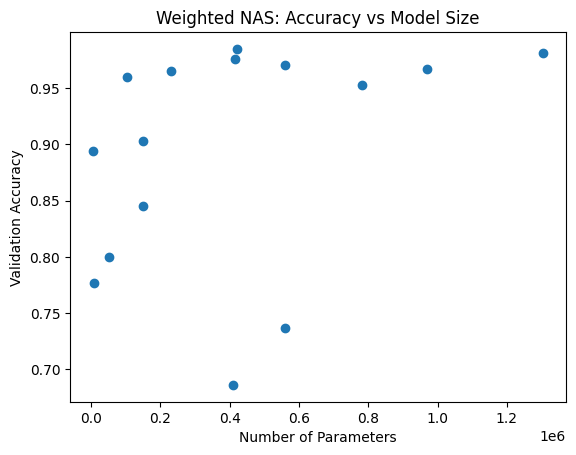

In [6]:
#Weighted sum approach
def architecture_metrics(model, val_acc, input_size=(1, 28, 28)):
    params = count_parameters(model)

    # Approximate FLOPs (simple proxy)
    flops = sum(p.numel() for p in model.parameters())

    return {
        "accuracy": val_acc,
        "params": params,
        "flops": flops
    }

def weighted_objective(metrics, w_acc=1.0, w_params=1e-6, w_flops=1e-7):
    return (
        w_acc * metrics["accuracy"]- w_params * metrics["params"]- w_flops * metrics["flops"]
    )

def multi_objective_random_search(search_space_size=20, epochs=3, device="cuda"):
    results = []

    for i in range(search_space_size):
        arch = generate_random_architecture()
        model = build_model(arch).to(device)

        val_acc = train_architecture(
            model,
            train_loader,
            val_loader,
            epochs=epochs,
            device=device,
            verbose=False
        )

        metrics = architecture_metrics(model, val_acc)
        score = weighted_objective(metrics)

        results.append({
            "architecture": arch,
            "metrics": metrics,
            "score": score
        })

    return sorted(results, key=lambda x: x["score"], reverse=True)


weighted_results = multi_objective_random_search(
    search_space_size=15,
    epochs=2,
    device=device
)

import matplotlib.pyplot as plt
import pandas as pd

table = []
for r in weighted_results[:5]:
    table.append({
        "Accuracy": r["metrics"]["accuracy"],
        "Parameters": r["metrics"]["params"],
        "FLOPs (proxy)": r["metrics"]["flops"],
        "Weighted Score": r["score"]
    })

df_weighted = pd.DataFrame(table)
print(df_weighted)

acc = [r["metrics"]["accuracy"] for r in weighted_results]
params = [r["metrics"]["params"] for r in weighted_results]

plt.figure()
plt.scatter(params, acc)
plt.xlabel("Number of Parameters")
plt.ylabel("Validation Accuracy")
plt.title("Weighted NAS: Accuracy vs Model Size")
plt.show()



Stage with 2 layers

Stage with 3 layers

Stage with 4 layers
   Accuracy  Parameters                                       Architecture
0    0.0781      821130  ([(maxpool, 128), (identity, 128), (conv5x5, 1...
1    0.0980      560266  ([(conv3x3, 128), (maxpool, 128), (conv3x3, 12...

Evaluating architecture 1/10
Validation Accuracy: 0.9478

Evaluating architecture 2/10
Validation Accuracy: 0.9618

Evaluating architecture 3/10
Validation Accuracy: 0.5303

Evaluating architecture 4/10
Validation Accuracy: 0.7784

Evaluating architecture 5/10
Validation Accuracy: 0.8892

Evaluating architecture 6/10
Validation Accuracy: 0.9814

Evaluating architecture 7/10
Validation Accuracy: 0.9741

Evaluating architecture 8/10
Validation Accuracy: 0.6760

Evaluating architecture 9/10
Validation Accuracy: 0.9505

Evaluating architecture 10/10
Validation Accuracy: 0.6928


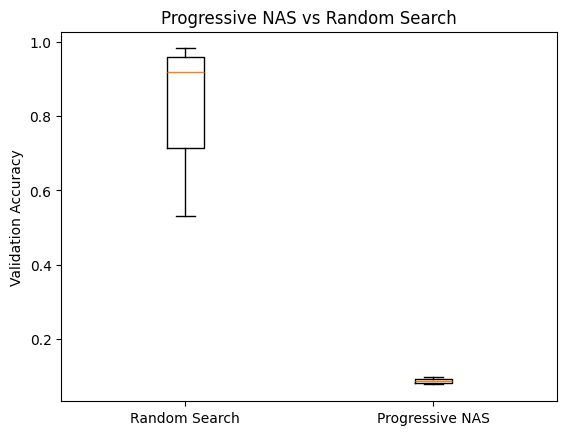

In [7]:
#Progressive
def progressive_nas(stages=[2, 3, 4], candidates_per_stage=5, device="cpu"):
    best_archs = []

    for num_layers in stages:
        print(f"\nStage with {num_layers} layers")

        candidates = []
        for _ in range(candidates_per_stage):
            arch = generate_random_architecture(num_layers,num_layers)
            model = build_model(arch).to(device)

            acc = train_architecture(
                model,
                train_loader,
                val_loader,
                epochs=3,
                device=device,
                verbose=False
            )

            candidates.append((arch, acc))

        candidates.sort(key=lambda x: x[1], reverse=True)
        best_archs = [c[0] for c in candidates[:2]]  # keep top-2

    return best_archs
    
import matplotlib.pyplot as plt
import pandas as pd

best_progressive_archs = progressive_nas(
    stages=[2, 3, 4],
    candidates_per_stage=4,
    device=device
)

progressive_results = []

for arch in best_progressive_archs:
    model = build_model(arch).to(device)

    acc = evaluate_architecture(
        model,
        test_loader,
        device=device
    )

    params = count_parameters(model)

    progressive_results.append({
        "Accuracy": acc,
        "Parameters": params,
        "Architecture": arch
    })

df_progressive = pd.DataFrame(progressive_results)
print(df_progressive)

random_results = random_search(
    search_space_size=10,
    epochs_per_arch=2,
    device=device
)

random_acc = [acc for _, acc in random_results]

plt.figure()
plt.boxplot([random_acc,df_progressive["Accuracy"]],labels=["Random Search", "Progressive NAS"])
plt.ylabel("Validation Accuracy")
plt.title("Progressive NAS vs Random Search")
plt.show()


**Progressive NAS underperformed Random Search because early-stage models were small and under-trained, demonstrating the importance of weight sharing and sufficient training in progressive architecture search.**

**Multi-objective NAS reveals a clear trade-off between accuracy and efficiency. Weighted optimization tends to favor compact architectures with slightly lower accuracy, while Pareto-optimal solutions provide a diverse set of architectures suitable for different deployment constraints. Progressive and iterative NAS significantly reduce search cost by pruning poor architectures early and reusing knowledge from previous search stages.**